# Module 7. Topic 14. Regularization and hyperparameter optimization

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/BetterED-Neoversity/DEEP-LEARNING-FOR-COMPUTER-VISION-AND-NLP/blob/main/notebooks/Module_7_Lecture_14_Class.ipynb)

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

import matplotlib.pyplot as plt

# Normalization techniques

In [2]:
# define transformations for the data
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))  # mean and standard deviation for MNIST
])

# download the complete MNIST data set
full_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)

# split the data set into training and validation
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

# create a test data set
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

# determine the batch size
batch_size = 64

# create data loaders
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Train set size: {len(train_dataset)}")
print(f"Validation set size: {len(val_dataset)}")
print(f"Test set size: {len(test_dataset)}")
print(f"Number of batches in train_loader: {len(train_loader)}")

100%|██████████| 9.91M/9.91M [00:04<00:00, 2.12MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 204kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.50MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 20.1MB/s]

Train set size: 48000
Validation set size: 12000
Test set size: 10000
Number of batches in train_loader: 750


In [3]:
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc1 = nn.Linear(784, 512)
        self.fc2 = nn.Linear(512, 512)
        self.fc3 = nn.Linear(512, 10)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        return self.fc3(x)

In [4]:
# no regularization

model = Net()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters())

num_epochs = 20

train_losses = []
train_accs = []

val_losses = []
val_accs = []

for epoch in range(num_epochs):
    model.train()
    train_loss = 0
    train_correct = 0
    train_total = 0

    for batch_idx, (data, target) in enumerate(train_loader):
        optimizer.zero_grad()
        output = model(data.view(data.size(0), -1))
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        _, predicted = output.max(1)
        train_total += target.size(0)
        train_correct += predicted.eq(target).sum().item()

    train_loss /= len(train_loader)
    train_accuracy = 100. * train_correct / train_total
    
    train_losses.append(train_loss)
    train_accs.append(train_accuracy)

    # validation step
    model.eval()
    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for data, target in val_loader:
            output = model(data.view(data.size(0), -1))
            loss = criterion(output, target)
            val_loss += loss.item()
            _, predicted = output.max(1)
            val_total += target.size(0)
            val_correct += predicted.eq(target).sum().item()

    val_loss /= len(val_loader)
    val_accuracy = 100. * val_correct / val_total
    
    val_losses.append(val_loss)
    val_accs.append(val_accuracy)

    print(f'Epoch [{epoch+1}/{num_epochs}]')
    print(f'Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.2f}%')
    print(f'Val Loss: {val_loss:.4f}, Val Accuracy: {val_accuracy:.2f}%')
    print('-' * 50)

Epoch [1/20]
Train Loss: 0.2183, Train Accuracy: 93.21%
Val Loss: 0.1300, Val Accuracy: 95.90%
--------------------------------------------------
Epoch [2/20]
Train Loss: 0.0927, Train Accuracy: 97.10%
Val Loss: 0.0987, Val Accuracy: 96.98%
--------------------------------------------------
Epoch [3/20]
Train Loss: 0.0638, Train Accuracy: 98.04%
Val Loss: 0.0868, Val Accuracy: 97.40%
--------------------------------------------------
Epoch [4/20]
Train Loss: 0.0505, Train Accuracy: 98.43%
Val Loss: 0.0935, Val Accuracy: 97.26%
--------------------------------------------------
Epoch [5/20]
Train Loss: 0.0413, Train Accuracy: 98.67%
Val Loss: 0.1014, Val Accuracy: 97.40%
--------------------------------------------------
Epoch [6/20]
Train Loss: 0.0367, Train Accuracy: 98.81%
Val Loss: 0.1078, Val Accuracy: 97.31%
--------------------------------------------------
Epoch [7/20]
Train Loss: 0.0263, Train Accuracy: 99.15%
Val Loss: 0.1181, Val Accuracy: 96.95%
-----------------------------

In [5]:
def visualize_training_history(train_losses, train_accs, val_losses, val_accs):
    epochs = range(1, len(train_losses) + 1)

    plt.figure(figsize=(12, 5))

    # loss plot
    plt.subplot(1, 2, 1)
    plt.plot(epochs, train_losses, 'b-', label='Train Loss')
    plt.plot(epochs, val_losses, 'r-', label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    # accuracy plot
    plt.subplot(1, 2, 2)
    plt.plot(epochs, train_accs, 'b-', label='Train Accuracy')
    plt.plot(epochs, val_accs, 'r-', label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.tight_layout()
    plt.show()

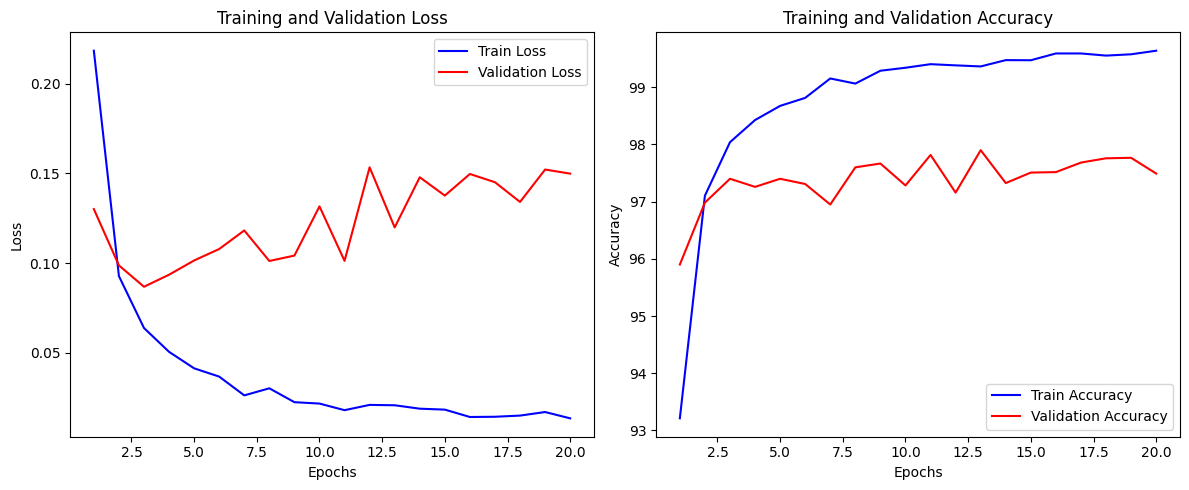

In [6]:
visualize_training_history(train_losses, train_accs, val_losses, val_accs)

Epoch [1/20]
Train Loss: 0.2274, Train Accuracy: 93.04%
Val Loss: 0.1361, Val Accuracy: 95.77%
--------------------------------------------------
Epoch [2/20]
Train Loss: 0.1131, Train Accuracy: 96.50%
Val Loss: 0.1231, Val Accuracy: 96.15%
--------------------------------------------------
Epoch [3/20]
Train Loss: 0.0920, Train Accuracy: 97.17%
Val Loss: 0.1460, Val Accuracy: 95.67%
--------------------------------------------------
Epoch [4/20]
Train Loss: 0.0836, Train Accuracy: 97.40%
Val Loss: 0.1122, Val Accuracy: 96.46%
--------------------------------------------------
Epoch [5/20]
Train Loss: 0.0727, Train Accuracy: 97.68%
Val Loss: 0.1176, Val Accuracy: 96.51%
--------------------------------------------------
Epoch [6/20]
Train Loss: 0.0675, Train Accuracy: 97.86%
Val Loss: 0.1041, Val Accuracy: 96.80%
--------------------------------------------------
Epoch [7/20]
Train Loss: 0.0643, Train Accuracy: 97.99%
Val Loss: 0.0908, Val Accuracy: 97.21%
-----------------------------

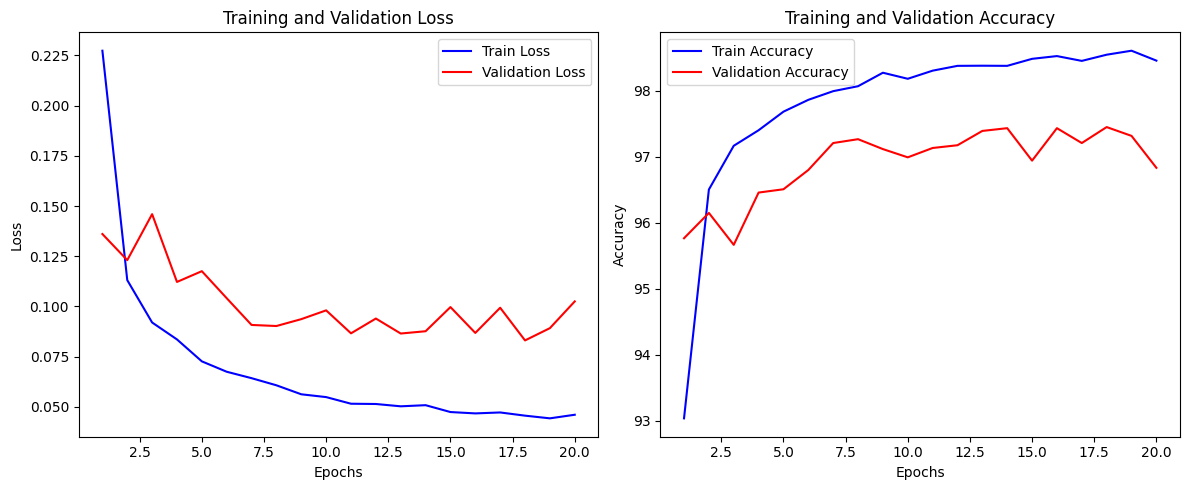

In [7]:
# L2 regularization

model = Net()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), weight_decay=1e-3)

num_epochs = 20

train_losses = []
train_accs = []

val_losses = []
val_accs = []

for epoch in range(num_epochs):
    model.train()
    train_loss = 0
    train_correct = 0
    train_total = 0

    for batch_idx, (data, target) in enumerate(train_loader):
        optimizer.zero_grad()
        output = model(data.view(data.size(0), -1))
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        _, predicted = output.max(1)
        train_total += target.size(0)
        train_correct += predicted.eq(target).sum().item()

    train_loss /= len(train_loader)
    train_accuracy = 100. * train_correct / train_total
    
    train_losses.append(train_loss)
    train_accs.append(train_accuracy)

    # validation step
    model.eval()
    val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for data, target in val_loader:
            output = model(data.view(data.size(0), -1))
            loss = criterion(output, target)
            val_loss += loss.item()
            _, predicted = output.max(1)
            val_total += target.size(0)
            val_correct += predicted.eq(target).sum().item()

    val_loss /= len(val_loader)
    val_accuracy = 100. * val_correct / val_total
    
    val_losses.append(val_loss)
    val_accs.append(val_accuracy)

    print(f'Epoch [{epoch+1}/{num_epochs}]')
    print(f'Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.2f}%')
    print(f'Val Loss: {val_loss:.4f}, Val Accuracy: {val_accuracy:.2f}%')
    print('-' * 50)
    
visualize_training_history(train_losses, train_accs, val_losses, val_accs)

In [8]:
# early stopping

model = Net()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters())
best_val_loss = float('inf')
patience = 2
counter = 0

train_losses = []
train_accs = []
val_losses = []
val_accs = []

for epoch in range(20):
    model.train()
    train_loss = 0
    train_correct = 0
    train_total = 0
    for batch_idx, (data, target) in enumerate(train_loader):
        optimizer.zero_grad()
        output = model(data.view(data.size(0), -1))
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
        _, predicted = output.max(1)
        train_total += target.size(0)
        train_correct += predicted.eq(target).sum().item()
    
    train_loss /= len(train_loader)
    train_acc = 100. * train_correct / train_total
    
    model.eval()
    val_loss = 0
    val_correct = 0
    val_total = 0
    with torch.no_grad():
        for data, target in val_loader:
            output = model(data.view(data.size(0), -1))
            val_loss += criterion(output, target).item()
            _, predicted = output.max(1)
            val_total += target.size(0)
            val_correct += predicted.eq(target).sum().item()
    
    val_loss /= len(val_loader)
    val_acc = 100. * val_correct / val_total
    
    # save results
    train_losses.append(train_loss)
    train_accs.append(train_acc)
    val_losses.append(val_loss)
    val_accs.append(val_acc)
    
    print(f'Epoch {epoch}: Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%, '
          f'Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%')
    
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        counter = 0
    else:
        counter += 1
        if counter >= patience:
            print(f"Early stopping at epoch {epoch}")
            break

Epoch 0: Train Loss: 0.2183, Train Acc: 93.26%, Val Loss: 0.1257, Val Acc: 96.15%
Epoch 1: Train Loss: 0.0945, Train Acc: 97.09%, Val Loss: 0.1051, Val Acc: 96.74%
Epoch 2: Train Loss: 0.0669, Train Acc: 97.89%, Val Loss: 0.1059, Val Acc: 96.98%
Epoch 3: Train Loss: 0.0494, Train Acc: 98.46%, Val Loss: 0.1131, Val Acc: 96.62%
Early stopping at epoch 3


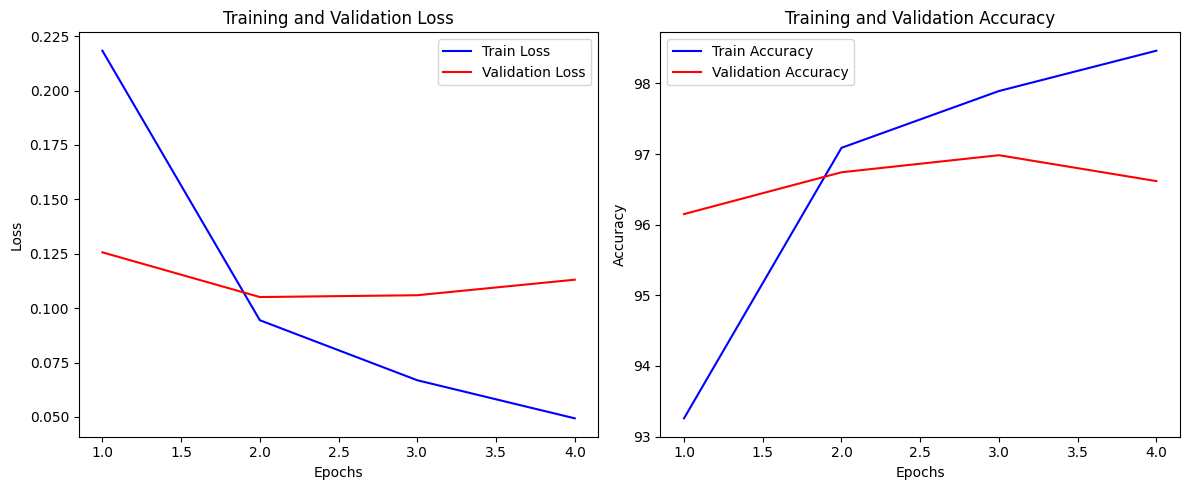

In [9]:
visualize_training_history(train_losses, train_accs, val_losses, val_accs)

In [10]:
class NetWithDropout(nn.Module):
    def __init__(self):
        super(NetWithDropout, self).__init__()
        self.fc1 = nn.Linear(784, 512)
        self.dropout1 = nn.Dropout(0.2)
        self.fc2 = nn.Linear(512, 512)
        self.dropout2 = nn.Dropout(0.2)
        self.fc3 = nn.Linear(512, 10)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = self.dropout1(x)
        x = torch.relu(self.fc2(x))
        x = self.dropout2(x)
        return self.fc3(x)

In [11]:
# dropout

model = NetWithDropout()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters())

train_losses = []
train_accs = []
val_losses = []
val_accs = []

for epoch in range(20):
    model.train()
    train_loss = 0
    train_correct = 0
    train_total = 0
    for batch_idx, (data, target) in enumerate(train_loader):
        optimizer.zero_grad()
        output = model(data.view(data.size(0), -1))
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
        _, predicted = output.max(1)
        train_total += target.size(0)
        train_correct += predicted.eq(target).sum().item()
    
    train_loss /= len(train_loader)
    train_acc = 100. * train_correct / train_total
    
    model.eval()
    val_loss = 0
    val_correct = 0
    val_total = 0
    with torch.no_grad():
        for data, target in val_loader:
            output = model(data.view(data.size(0), -1))
            val_loss += criterion(output, target).item()
            _, predicted = output.max(1)
            val_total += target.size(0)
            val_correct += predicted.eq(target).sum().item()
    
    val_loss /= len(val_loader)
    val_acc = 100. * val_correct / val_total
    
    # save results
    train_losses.append(train_loss)
    train_accs.append(train_acc)
    val_losses.append(val_loss)
    val_accs.append(val_acc)
    
    print(f'Epoch {epoch}: Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%, '
          f'Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%')

Epoch 0: Train Loss: 0.2478, Train Acc: 92.45%, Val Loss: 0.1273, Val Acc: 96.19%
Epoch 1: Train Loss: 0.1186, Train Acc: 96.41%, Val Loss: 0.1090, Val Acc: 96.72%
Epoch 2: Train Loss: 0.0955, Train Acc: 97.04%, Val Loss: 0.1068, Val Acc: 97.04%
Epoch 3: Train Loss: 0.0751, Train Acc: 97.67%, Val Loss: 0.1108, Val Acc: 96.66%
Epoch 4: Train Loss: 0.0655, Train Acc: 97.94%, Val Loss: 0.0980, Val Acc: 97.22%
Epoch 5: Train Loss: 0.0594, Train Acc: 98.15%, Val Loss: 0.0989, Val Acc: 97.22%
Epoch 6: Train Loss: 0.0541, Train Acc: 98.28%, Val Loss: 0.0981, Val Acc: 97.53%
Epoch 7: Train Loss: 0.0503, Train Acc: 98.43%, Val Loss: 0.0933, Val Acc: 97.58%
Epoch 8: Train Loss: 0.0477, Train Acc: 98.55%, Val Loss: 0.0964, Val Acc: 97.67%
Epoch 9: Train Loss: 0.0446, Train Acc: 98.64%, Val Loss: 0.0861, Val Acc: 97.98%
Epoch 10: Train Loss: 0.0394, Train Acc: 98.77%, Val Loss: 0.1002, Val Acc: 97.56%
Epoch 11: Train Loss: 0.0388, Train Acc: 98.81%, Val Loss: 0.1083, Val Acc: 97.66%
Epoch 12: Trai

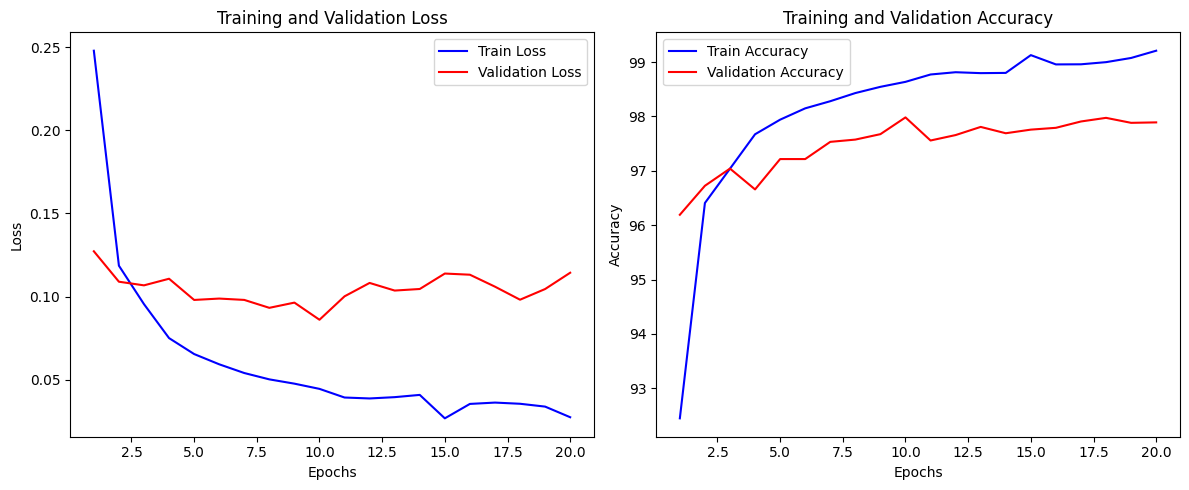

In [12]:
visualize_training_history(train_losses, train_accs, val_losses, val_accs)

In [13]:
class NetWithBN(nn.Module):
    def __init__(self):
        super(NetWithBN, self).__init__()
        self.fc1 = nn.Linear(784, 256)
        self.bn1 = nn.BatchNorm1d(256)
        self.fc2 = nn.Linear(256, 256)
        self.bn2 = nn.BatchNorm1d(256)
        self.fc3 = nn.Linear(256, 10)

    def forward(self, x):
        x = torch.relu(self.bn1(self.fc1(x)))
        x = torch.relu(self.bn2(self.fc2(x)))
        return self.fc3(x)

Epoch 0: Train Loss: 0.2039, Train Acc: 93.95%, Val Loss: 0.1060, Val Acc: 96.82%
Epoch 1: Train Loss: 0.0878, Train Acc: 97.28%, Val Loss: 0.0928, Val Acc: 97.01%
Epoch 2: Train Loss: 0.0598, Train Acc: 98.04%, Val Loss: 0.0804, Val Acc: 97.52%
Epoch 3: Train Loss: 0.0447, Train Acc: 98.61%, Val Loss: 0.0827, Val Acc: 97.47%
Epoch 4: Train Loss: 0.0381, Train Acc: 98.77%, Val Loss: 0.0789, Val Acc: 97.58%
Epoch 5: Train Loss: 0.0333, Train Acc: 98.90%, Val Loss: 0.0784, Val Acc: 97.71%
Epoch 6: Train Loss: 0.0268, Train Acc: 99.08%, Val Loss: 0.0759, Val Acc: 97.78%
Epoch 7: Train Loss: 0.0239, Train Acc: 99.20%, Val Loss: 0.0726, Val Acc: 97.86%
Epoch 8: Train Loss: 0.0219, Train Acc: 99.25%, Val Loss: 0.0791, Val Acc: 97.86%
Epoch 9: Train Loss: 0.0197, Train Acc: 99.34%, Val Loss: 0.0750, Val Acc: 97.88%
Epoch 10: Train Loss: 0.0170, Train Acc: 99.44%, Val Loss: 0.0891, Val Acc: 97.67%
Epoch 11: Train Loss: 0.0132, Train Acc: 99.58%, Val Loss: 0.0878, Val Acc: 97.75%
Epoch 12: Trai

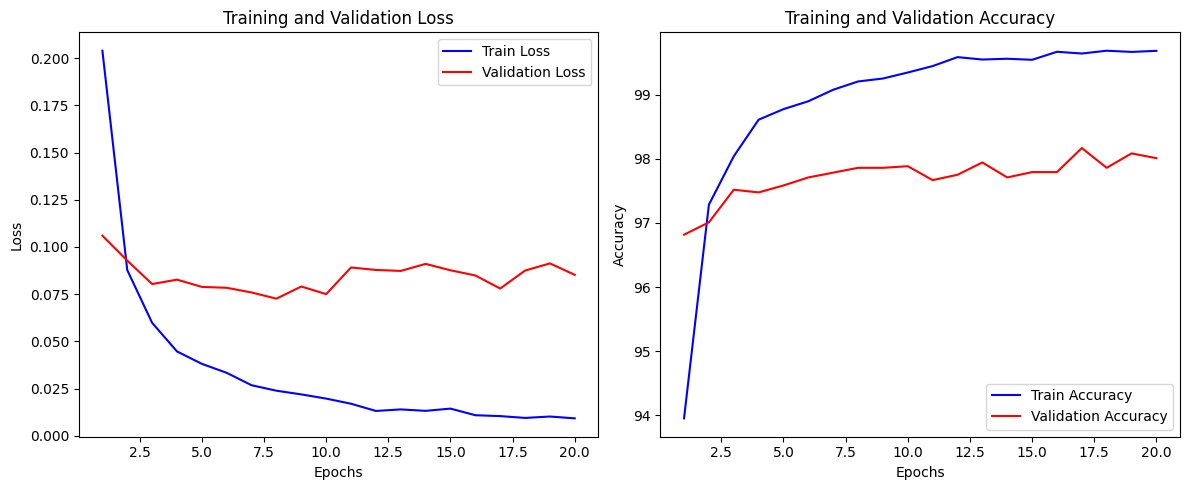

In [14]:
# BN

model = NetWithBN()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters())

train_losses = []
train_accs = []
val_losses = []
val_accs = []

for epoch in range(20):
    model.train()
    train_loss = 0
    train_correct = 0
    train_total = 0
    for batch_idx, (data, target) in enumerate(train_loader):
        optimizer.zero_grad()
        output = model(data.view(data.size(0), -1))
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
        _, predicted = output.max(1)
        train_total += target.size(0)
        train_correct += predicted.eq(target).sum().item()
    
    train_loss /= len(train_loader)
    train_acc = 100. * train_correct / train_total
    
    model.eval()
    val_loss = 0
    val_correct = 0
    val_total = 0
    with torch.no_grad():
        for data, target in val_loader:
            output = model(data.view(data.size(0), -1))
            val_loss += criterion(output, target).item()
            _, predicted = output.max(1)
            val_total += target.size(0)
            val_correct += predicted.eq(target).sum().item()
    
    val_loss /= len(val_loader)
    val_acc = 100. * val_correct / val_total
    
    # save results
    train_losses.append(train_loss)
    train_accs.append(train_acc)
    val_losses.append(val_loss)
    val_accs.append(val_acc)
    
    print(f'Epoch {epoch}: Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%, '
          f'Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%')
    
    
visualize_training_history(train_losses, train_accs, val_losses, val_accs)

# Hyperparameter optimization

In [15]:
!pip install optuna

import optuna

In [16]:
class Net(nn.Module):
    def __init__(self, dropout_rate, use_batchnorm):
        super(Net, self).__init__()
        self.fc1 = nn.Linear(784, 512)
        self.fc2 = nn.Linear(512, 512)
        self.fc3 = nn.Linear(512, 10)
        self.dropout = nn.Dropout(dropout_rate)
        self.use_batchnorm = use_batchnorm
        if use_batchnorm:
            self.bn1 = nn.BatchNorm1d(512)
            self.bn2 = nn.BatchNorm1d(512)

    def forward(self, x):
        x = x.view(-1, 784)
        x = self.fc1(x)
        if self.use_batchnorm:
            x = self.bn1(x)
        x = torch.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)
        if self.use_batchnorm:
            x = self.bn2(x)
        x = torch.relu(x)
        x = self.dropout(x)
        return self.fc3(x)

In [17]:
def objective(trial):
    # determine hyperparameters for optimization
    lr = trial.suggest_float('lr', 1e-5, 1e-1, log=True)
    dropout_rate = trial.suggest_float('dropout_rate', 0.1, 0.5)
    use_batchnorm = trial.suggest_categorical('use_batchnorm', [True, False])
    batch_size = trial.suggest_categorical('batch_size', [32, 64, 128, 256])
    
    # create a model with selected hyperparameters
    model = Net(dropout_rate, use_batchnorm)
    
    # training settings
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    
    # model training
    model.train()
    for epoch in range(10):  # let's limit it to 10 epochs for speed
        for batch_idx, (data, target) in enumerate(train_loader):
            optimizer.zero_grad()
            output = model(data)
            loss = criterion(output, target)
            loss.backward()
            optimizer.step()
        
        # Early stopping
        if epoch > 2 and loss.item() > prev_loss:
            break
        prev_loss = loss.item()
    
    # model evaluation
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for data, target in DataLoader(val_dataset, batch_size=1000):
            output = model(data)
            _, predicted = torch.max(output.data, 1)
            total += target.size(0)
            correct += (predicted == target).sum().item()
    
    accuracy = correct / total
    return accuracy

In [18]:
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=100)

print('Number of finished trials:', len(study.trials))
print('Best trial:')
trial = study.best_trial
print('  Value: ', trial.value)
print('  Params: ')
for key, value in trial.params.items():
    print('    {}: {}'.format(key, value))

[I 2026-11-17 14:28:54,798] A new study created in memory with name: no-name-4757fcaa-b5e1-45a1-9b70-259df9cf8537
[I 2026-11-17 14:29:17,741] Trial 0 finished with value: 0.9754166666666667 and parameters: {'lr': 0.0006138939168151581, 'dropout_rate': 0.10751575112040618, 'use_batchnorm': True, 'batch_size': 128}. Best is trial 0 with value: 0.9754166666666667.
[I 2026-11-17 14:29:44,556] Trial 1 finished with value: 0.9425833333333333 and parameters: {'lr': 2.5097275034550084e-05, 'dropout_rate': 0.10717583185704638, 'use_batchnorm': True, 'batch_size': 256}. Best is trial 0 with value: 0.9754166666666667.
[I 2026-11-17 14:30:22,321] Trial 2 finished with value: 0.10566666666666667 and parameters: {'lr': 0.082686454820071, 'dropout_rate': 0.4788890210865483, 'use_batchnorm': False, 'batch_size': 256}. Best is trial 0 with value: 0.9754166666666667.
[I 2026-11-17 14:30:48,118] Trial 3 finished with value: 0.9760833333333333 and parameters: {'lr': 0.0016740754834516708, 'dropout_rate': 

Number of finished trials: 100
Best trial:
  Value:  0.9795
  Params: 
    lr: 0.00047912627060345064
    dropout_rate: 0.22237328146598093
    use_batchnorm: True
    batch_size: 32


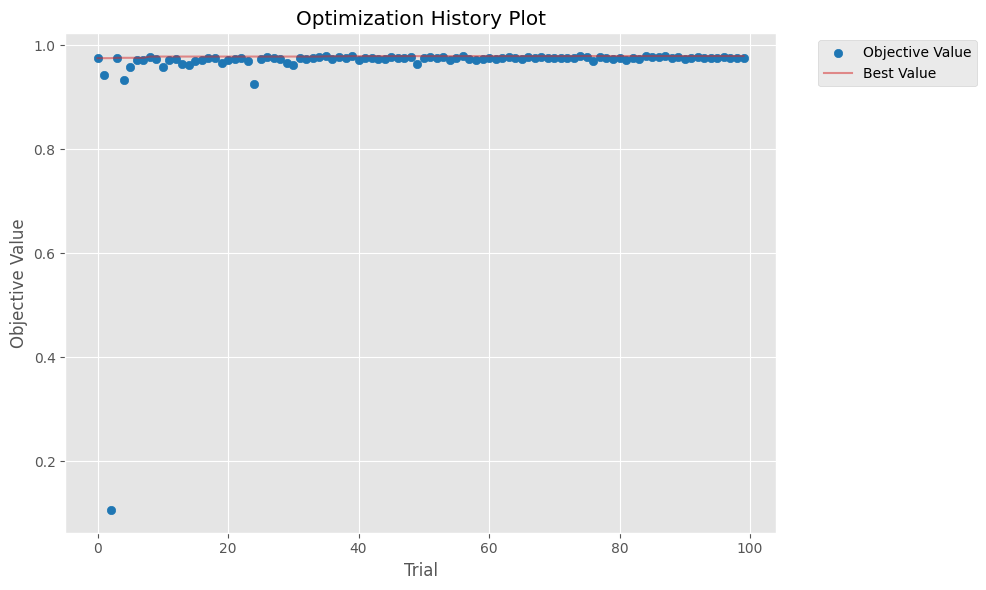

In [19]:
import warnings

# The matplotlib versions of the Optuna plots are marked as experimental: hide this notice
warnings.filterwarnings('ignore', category=optuna.exceptions.ExperimentalWarning)
# Optuna creates the figures itself, so their size is set here (plt.figure() would only add an empty figure)
plt.rcParams['figure.figsize'] = (10, 6)

# 1. Optimization history plot
optuna.visualization.matplotlib.plot_optimization_history(study)
plt.show()

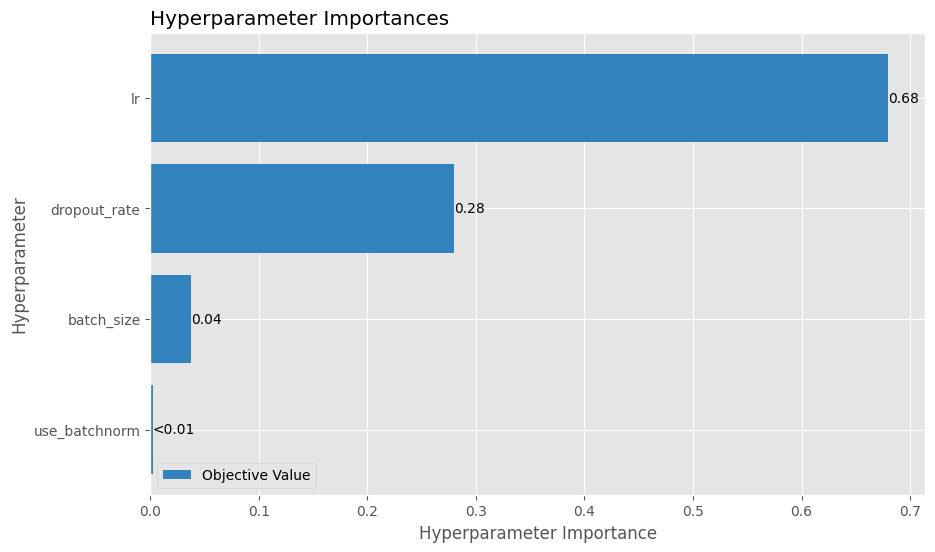

In [20]:
# 2. Parameter importance plot
optuna.visualization.matplotlib.plot_param_importances(study)
plt.show()

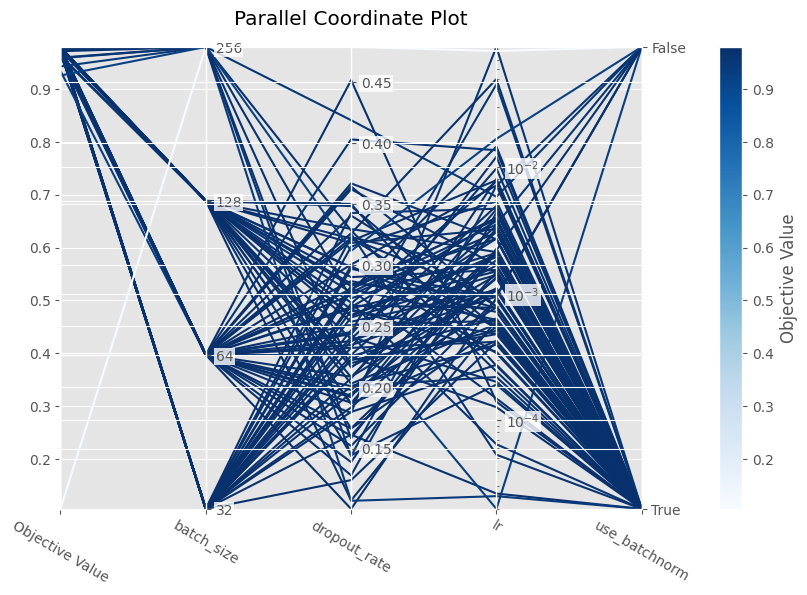

In [21]:
# 3. Parameters interaction plot
ax = optuna.visualization.matplotlib.plot_parallel_coordinate(study)
# a light background under the tick labels, so that the lines do not hide them
for axis in ax.figure.axes:
    for label in axis.get_yticklabels():
        label.set_bbox(dict(facecolor='white', alpha=0.8, edgecolor='none', pad=1))
plt.show()

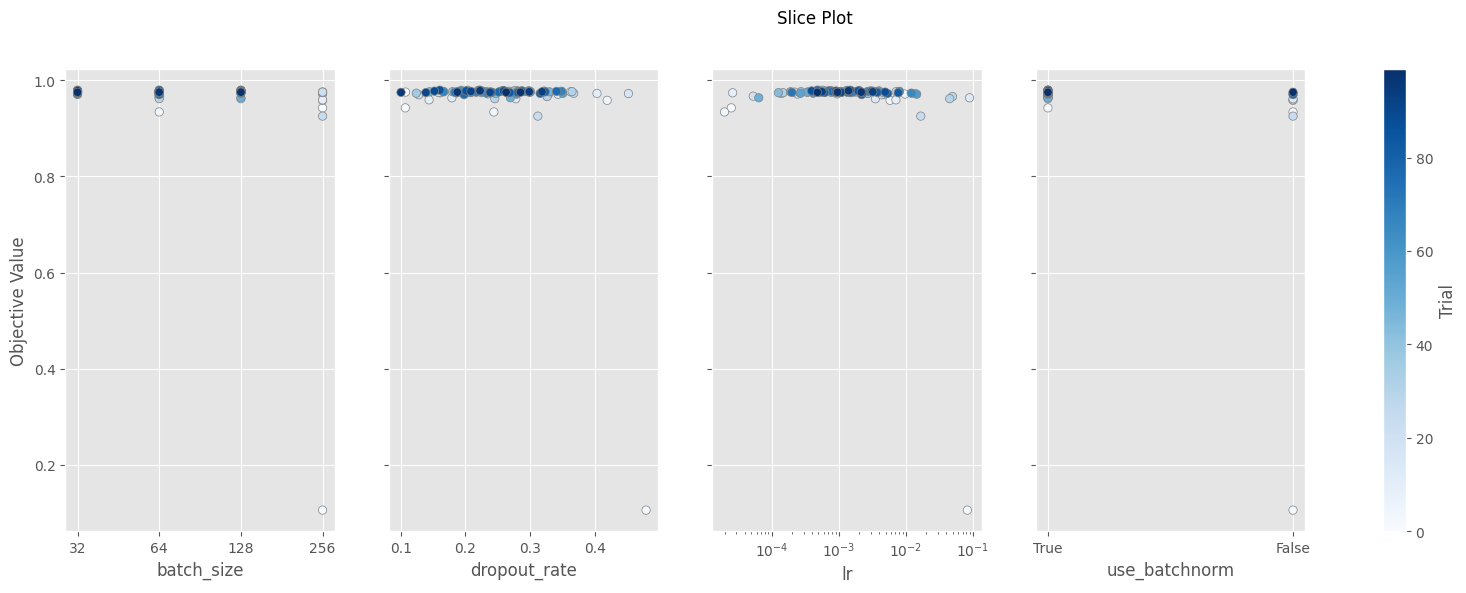

In [22]:
# 4. Parameter value distribution plot
optuna.visualization.matplotlib.plot_slice(study)
plt.show()

The next four plots are interactive versions of the plots above (plotly): in Colab or Jupyter you can hover over the points and zoom in. The copy of this notebook saved in the repository shows them as static images.

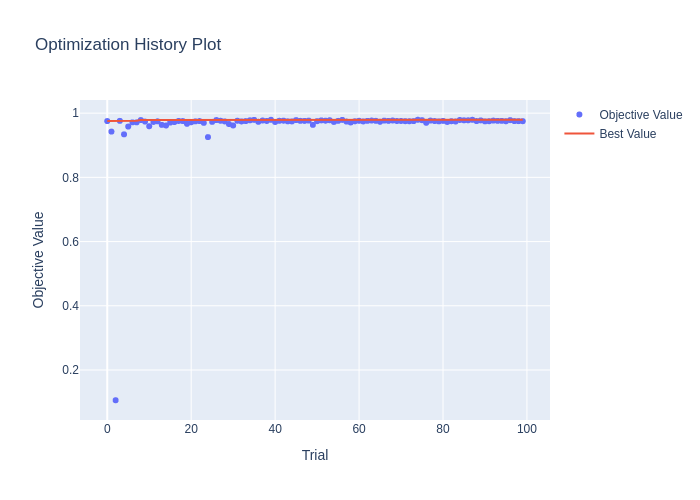

In [23]:
# 5. Interactive optimization plot
fig = optuna.visualization.plot_optimization_history(study)
fig.show()

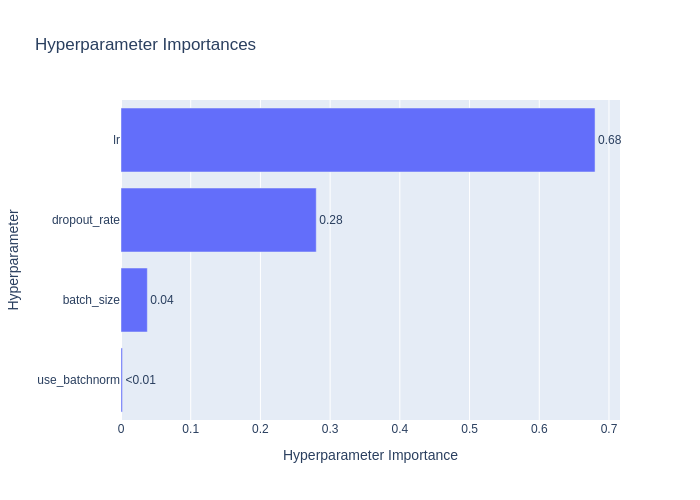

In [24]:
# 6. Interactive parameter importance plot
fig = optuna.visualization.plot_param_importances(study)
fig.show()

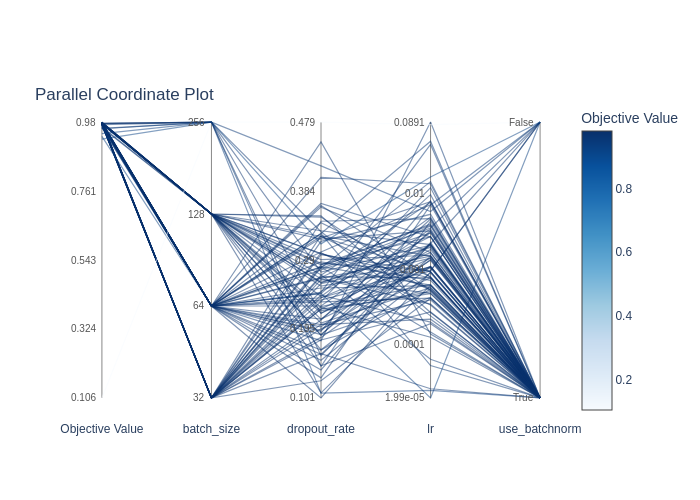

In [25]:
# 7. Interactive interaction of parameters plot
fig = optuna.visualization.plot_parallel_coordinate(study)
fig.show()

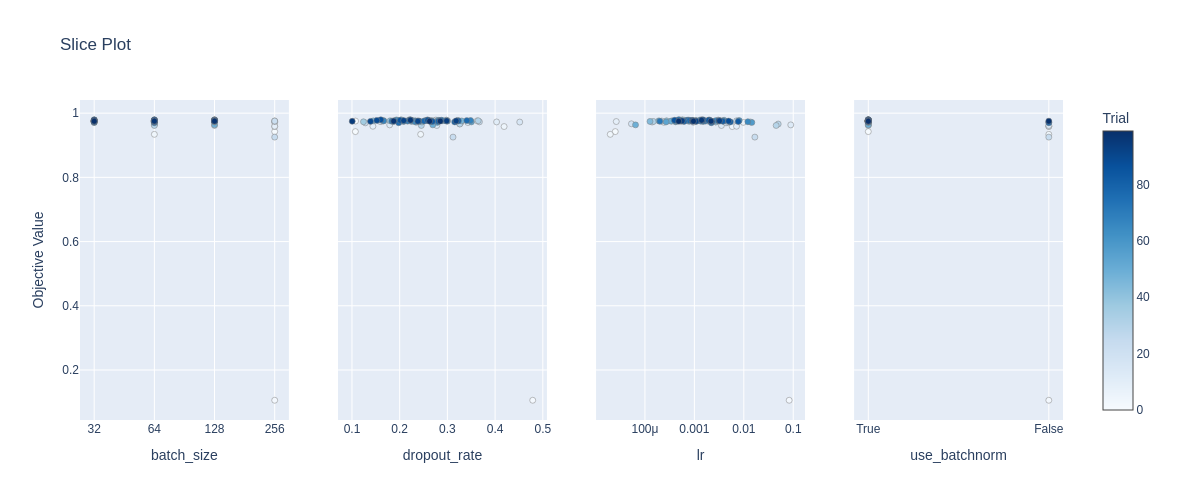

In [26]:
# 8. Interactive parameter value distribution plot
fig = optuna.visualization.plot_slice(study)
fig.show()